# Лобораторна робота №1

Ми з вами обробляємо данні продажів у інтернет магазині. Керівництво магазину вирішило деякі товари продавати по спеціальній пропозиції (с.п.)  
Умови цієї пропозиції:
- доставка замовлень з товарами по с.п. безкоштовно
- вартість доставки всіх інших замовлень - 20грн
- якщо товар по с.п. не підійшов то його можна повернути бкзкоштовно (і лише його!)

Данні. Кожний рядок у файлі - одне замовлення для клієнта магазину:
- total: сумарна віртість замовлення  
- return: чи повернуто товар по с.п.  (True = повернуто)
- special_proposition: вартість товару зі с.п.  

Керівництво магазину зрозуміло, що деякі замовники використовують с.п. задля безкоштовного доставлення інших товарів. Нам дана задача побудувати аналітику та орієнтовно оцінити об'єми недоброчесних дій деяких замовників

In [37]:
import pandas as pd
data = pd.read_csv("data.csv")
data.head(4)

,Unnamed: 0,total,return,special_proposition
0,0,88.678970,False,9.141027
1,1,104.085105,True,8.569498
2,2,136.883561,False,50.300859
3,3,122.467426,False,44.532713


# Позначення
$1\leq i \leq n$  
$\xi_i + \eta_i$ - сумарна вартість замовлення (total)  
$\eta_i$ - вартість товару із с.п. (special_proposition)  
$\xi_i$ - вартість інших товарів (без с.п.) (?)  

$p_i$ - чи був товар із с.п. повернуто (return)


# 1. Об'єми повернень
В даній частині роботи нас цікавить ймовірніть того, що користувач поверне товар

### Задачі:
1. Оцініть ймовірніть повернення товару із с.п. $p$
2. Побудуйте для цієї ймовірності $p$ довірчі інтервали із рівнями 95% та 99%

(Підказка: випробування Бернулі)

In [38]:
data = pd.read_csv("data.csv")
n = len(data)
r = data['return'].sum()
p = r/n
print("p =", p, "\n")

for level in [0.95, 0.99]:
    a = 1 - level

    from scipy import stats
    z = stats.norm.ppf(1 - a / 2)
    se = (p * (1 - p) / n) ** (0.5)

    st = p - z*se
    ed = p + z*se


    print(f"--- {int(level * 100)}% ---")
    print(f"({st * 100:.2f}%, ", f"{ed * 100:.2f}%)\n")

p = 0.278 

--- 95% ---
(25.02%,  30.58%)

--- 99% ---
(24.15%,  31.45%)



# 2. Вартість товарів по с.п.
В даній секції нас цікавить аналітика цін товарів по с.п.

### Задачі:
1. Оцініть середню вартість товару із с.п. $\mu$
2. Побудуйте для середньої вартості товару із с.п. $\mu$ довірчі інтервали із рівнями 95% та 99%

### Задачі:
Припустимо, що вартість товарів по с.п. ($\eta_i$) має розподіл $Exp(\lambda k)$, k>0, $\lambda$>0  
1. Побудуйте гістограму та еміричну функцію розподілу для ціни товарів по с.п.
2. Оцініть параметр $\lambda k$ розподілу
3. Побудуйте теоретичну функцію розподілу, в який підставите оцінку $\lambda k$

(Підказка: $\lambda k$ - один параметр, який треба оцінити)

In [39]:

n_sp = len(data["special_proposition"])
mu = data["special_proposition"].sum()/n_sp
print(f"середня вартість = {mu}\n")

for level in [0.95, 0.99]:
    a = 1 - level

    from scipy import stats
    t_val = stats.t.ppf(1 - a / 2, df = n_sp-1)
    se = (p * (1 - p) / n) ** (0.5)
    s = data["special_proposition"].std(ddof=1)

    st = mu - t_val * s / (n**0.5)
    ed = mu + t_val * s / (n**0.5)


    print(f"--- {int(level * 100)}% ---")
    print(f"({st:.2f}, ", f"{ed:.2f})\n")




середня вартість = 31.32330130624987

--- 95% ---
(29.36,  33.29)

--- 99% ---
(28.74,  33.91)



λk ~= 0.031925


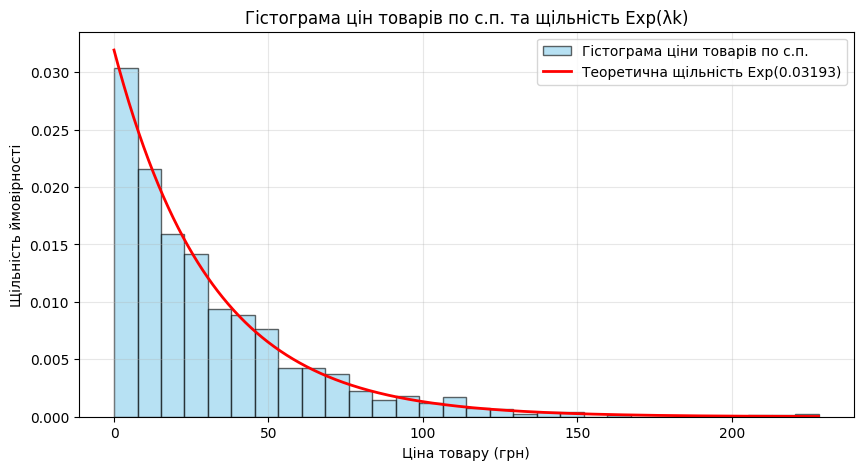

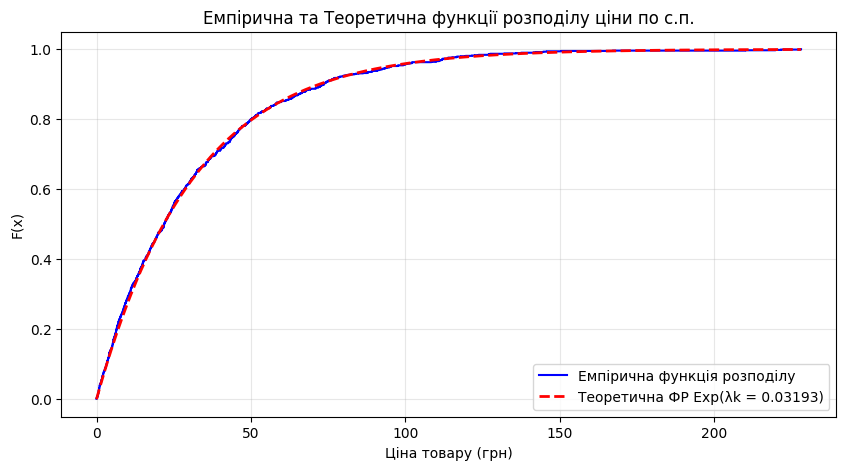

In [40]:
import matplotlib.pyplot as plt
import numpy as np
lk = 1.0 / mu
print(f"\u03bbk ~= {lk:.6f}")

x_grid = np.linspace(0, data['special_proposition'].max(), 1000)

plt.figure(figsize=(10, 5))
plt.hist(
    data['special_proposition'],
    bins=30,
    density=True,
    alpha=0.6,
    color='skyblue',
    edgecolor='black',
    label='Гістограма ціни товарів по с.п.',
)

f_theoretical = lk * np.exp(-lk * x_grid)
plt.plot(
    x_grid,
    f_theoretical,
    'r-',
    lw=2,
    label=f'Теоретична щільність Exp({lk:.5f})',
)

plt.title('Гістограма цін товарів по с.п. та щільність Exp(\u03bbk)')
plt.xlabel('Ціна товару (грн)')
plt.ylabel('Щільність ймовірності')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


x_sorted = np.sort(data['special_proposition'])
y_edf = np.arange(1, len(x_sorted) + 1) / len(x_sorted)

df_theoretical = 1 - np.exp(-lk * x_grid)

plt.figure(figsize=(10, 5))
plt.step(
    x_sorted,
    y_edf,
    label='Емпірична функція розподілу ',
    color='blue',
    where='post',
)
plt.plot(
    x_grid,
    df_theoretical,
    label=f'Теоретична ФР Exp(\u03bbk = {lk:.5f})',
    color='red',
    linestyle='--',
    lw=2,
)

plt.title(
    'Емпірична та Теоретична функції розподілу ціни по с.п.'
)
plt.xlabel('Ціна товару (грн)')
plt.ylabel('F(x)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3. Інші товари
Тут нас цікавлять інші товари (без с.п.) та розподіл їх вартостей.
Тут $\xi_i$=$total - special\_proposition$

### Задачі:
1. Оцініть середню вартість товару без с.п. $\mu$
2. Побудуйте середньої вартості товару без с.п. $\mu$ довірчі інтервали із рівнями 95% та 99%

Припустимо, що вартість товарів без с.п. ($\xi_i$) має розподіл $Exp(\lambda)$, $\lambda$>0  
Увага! Тут припускаємо, що $\lambda$ тут і в пункті 2 - один і той же параметр, тобто  
($\eta_i$) має розподіл $Exp(\lambda k)$,  
($\xi_i$) має розподіл $Exp(\lambda)$,  
 k>0, $\lambda$>0  

### Задачі:
1. Побудуйте гістограму та еміричну функцію розподілу для ціни товарів інших товарів
2. Оцініть параметр $\lambda$ розподілу. Чи буде оцінка незміщеною? Консистентною?
3. Побудуйте теоретичну функцію розподілу, в який підставите оцінку $\lambda$

### Задача із:
1. (*) Запропонуйте оцінку для параметра $k$. Тут можна використати знання про розподіли цін товарів з та без с.п.
2. (*) за доведення консистентності, чи оцінка зміщена?

(*) означає - можна використати генеративний ШІ, але обов'язково розібрати його доведення так, щоб могли відповідати на мої питання

μ ~= 99.17 грн
--- 95% ---
(93.11,  105.23)

--- 99% ---
(91.20,  107.14)


λ ~= 0.010084


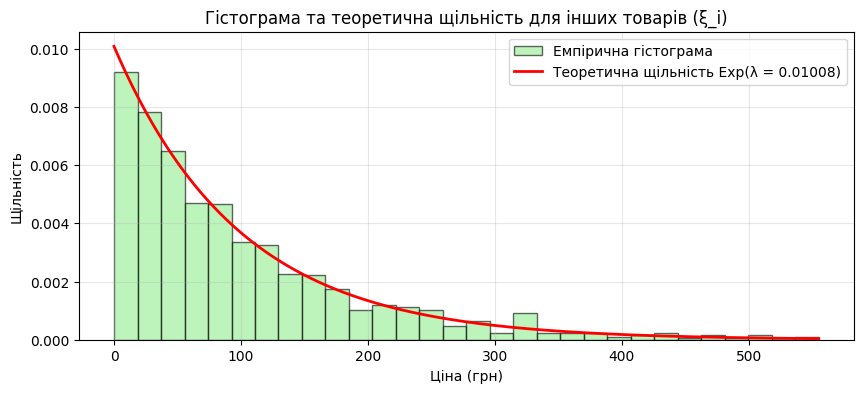

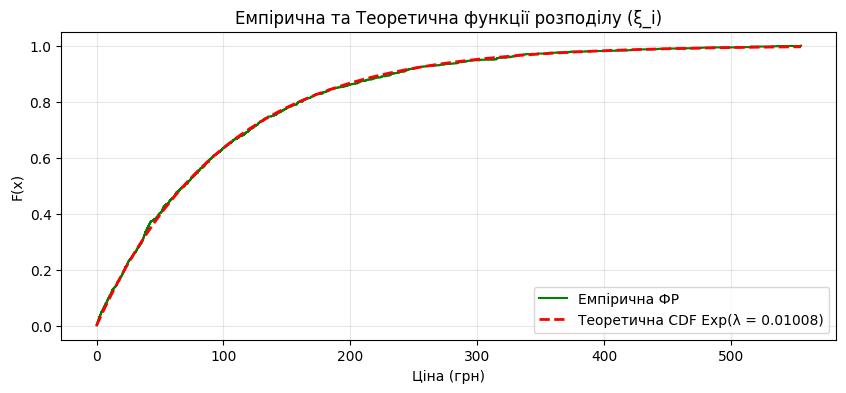

In [41]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

data['xi'] = data['total'] - data['special_proposition']

# ------

mu = data['xi'].mean()
n_non_sp = len(data['xi'])


print(f"\u03bc ~= {mu:.2f} грн")


for level in [0.95, 0.99]:
  a = 1 - level
  t_val = stats.t.ppf(1 - a / 2, df = n_non_sp-1)
  s = data['xi'].std(ddof=1)
  margin = t_val * s / (n**0.5)
  st = mu - margin
  ed = mu + margin

  print(f"--- {int(level * 100)}% ---")
  print(f"({st:.2f}, ", f"{ed:.2f})\n")


# ------
lambda_ = 1.0 / mu
print(f"\n\u03bb ~= {lambda_:.6f}")

x_grid = np.linspace(0, data['xi'].max(), 1000)

plt.figure(figsize=(10, 4))
plt.hist(
    data['xi'],
    bins=30,
    density=True,
    alpha=0.6,
    color='lightgreen',
    edgecolor='black',
    label='Емпірична гістограма',
)
plt.plot(
    x_grid,
    lambda_ * np.exp(-lambda_ * x_grid),
    'r-',
    lw=2,
    label=f'Теоретична щільність Exp(\u03bb = {lambda_:.5f})',
)
plt.title('Гістограма та теоретична щільність для інших товарів (\u03be_i)')
plt.xlabel('Ціна (грн)')
plt.ylabel('Щільність')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

x_sorted = np.sort(data['xi'])
y_edf = np.arange(1, n + 1) / n
df_theoretical = 1 - np.exp(-lambda_ * x_grid)

plt.figure(figsize=(10, 4))
plt.step(
    x_sorted, y_edf, label='Емпірична ФР', color='green', where='post'
)
plt.plot(
    x_grid,
    df_theoretical,
    'r--',
    lw=2,
    label=f'Теоретична CDF Exp(\u03bb = {lambda_:.5f})',
)
plt.title('Емпірична та Теоретична функції розподілу (\u03be_i)')
plt.xlabel('Ціна (грн)')
plt.ylabel('F(x)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [42]:
mean_non_sp = data['xi'].mean()  # \bar{\xi}
mean_sp = data['special_proposition'].mean()  # \bar{\eta}

k = mean_non_sp/ mean_sp

print(f"k ~= {k:.4f}")
print("зміщена для скінченного розміру вибірки, \n асимптотично(на нескінченності) - не зміщена ")

k ~= 3.1659
зміщена для скінченного розміру вибірки, 
 асимптотично(на нескінченності) - не зміщена 


# 4. Доля с.п. у замовлені

В цьому розділі нас цікавить частка товарів з с.п. у замовленні. Тобто, величини $\frac{\eta_i}{\xi_i+\eta_i}$. Можливо, вони якось пов'язані із поверненнями.
Чи залежать поверення від частки акційних товарів? Доведіть! (побудуйте аналітику!)

In [43]:
import matplotlib.pyplot as plt
import scipy.stats as stats

data['share_sp'] = data['special_proposition'] / data['total']


share_returned = data[data['return'] == True]['share_sp']
share_not_returned = data[data['return'] == False]['share_sp']

print(f"Середня частка с.п. (ПОВЕРНУТО):    {share_returned.mean():.4f}")
print(f"Середня частка с.п. (НЕ повернуто): {share_not_returned.mean():.4f}\n")

# 3. Двовибірковий t-тест Стьюдента
t_stat, p_value = stats.ttest_ind(
    share_returned, share_not_returned, equal_var=False
)

print(f"t-статистика: {t_stat:.4f}")
print(f"p-value:      {p_value:.4e}")




Середня частка с.п. (ПОВЕРНУТО):    0.0481
Середня частка с.п. (НЕ повернуто): 0.4207

t-статистика: -39.4864
p-value:      2.0603e-187



 (2.0603e-187) < 0.05
повернення залежать від частки акційних товарів



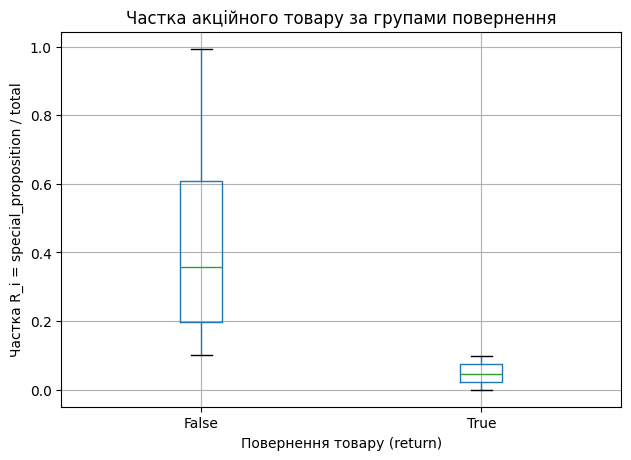

In [44]:


print(f"\n ({p_value:.4e}) < {0.05}")
print("повернення залежать від частки акційних товарів\n")


data.boxplot(column='share_sp', by='return', grid=True, figsize=(7, 5))
plt.title('Частка акційного товару за групами повернення')
plt.suptitle('')
plt.xlabel('Повернення товару (return)')
plt.ylabel('Частка R_i = special_proposition / total')
plt.show()

У припущенні, що ($\eta_i$) має розподіл $Exp(\lambda k)$,  та ($\xi_i$) має розподіл $Exp(\lambda)$

## Задачі по варіантам:

3. Чи можливо лише по вибірці з $\frac{\xi_i}{\eta_i}$ оцінити параметри $\lambda$ та $k$?



Нехай $\xi_i \sim Exp(\lambda)$ та $\eta_i \sim Exp(\lambda k)$ є незалежними показниковими випадковими величинами.
Їхні щільності ймовірностей мають вигляд:
* $f_\xi(x) = \lambda e^{-\lambda x}, \quad x > 0$
* $f_\eta(y) = \lambda k e^{-\lambda k y}, \quad y > 0$

Знайдемо теоретичну функцію розподілу відношення $W = \frac{\xi}{\eta}$ для $w > 0$:

$$F_W(w) = \mathbb{P}\left(\frac{\xi}{\eta} \le w\right) = \mathbb{P}(\xi \le w \eta) = \int_{0}^{\infty} \left( \int_{0}^{w y} \lambda e^{-\lambda x} dx \right) \lambda k e^{-\lambda k y} dy$$


$$\int_{0}^{w y} \lambda e^{-\lambda x} dx = 1 - e^{-\lambda w y}$$


$$F_W(w) = \int_{0}^{\infty} (1 - e^{-\lambda w y}) \cdot \lambda k e^{-\lambda k y} dy = 1 - \int_{0}^{\infty} \lambda k e^{-\lambda y (k + w)} dy$$

Після інтегрування отримуємо підсумкову формулу функції розподілу:
$$F_W(w) = 1 - \frac{\lambda k}{\lambda (k + w)} = 1 - \frac{k}{k + w} = \frac{w}{k + w}$$

---



1. $\lambda$ скоротилось $\implies$ Оцінити параметр $\lambda$ лише за вибіркою відношень $W_i$ неможливо.

2. Розподіл $W$ містить параметр $k$, тому оцінити $k$ можливо.
   Наприклад, через медіану:
   $$F_W(\text{Med}) = 0.5 \implies \frac{\text{Med}}{k + \text{Med}} = 0.5 \implies \mathbf{{k} = \text{Med}(W)}$$

In [45]:
W = data['xi'] / data['special_proposition']

k = W.median()

print(f"для наданої вибірки k ~= {k:.4f}")

для наданої вибірки k ~= 3.2894
